# Clustering Notebook
### This notebook is used to do clustering experiments and analysing them. The clustering method to be used is k-means.

In [ ]:
# Import the necessary functions from the clustering module
from src.clustering import fit_kmeans, calculate_inertia, analyze_clusters
from src.data import X_img_train, y_img_train, X_img_val, y_img_val, X_sent_train, y_sent_train, X_sent_val, y_sent_val
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from itertools import combinations

### 1. Clustering images

k= 1 | Best training inertia: 13,893.62
k= 2 | Best training inertia: 13,478.84
k= 3 | Best training inertia: 13,215.17
k= 5 | Best training inertia: 12,915.71
k= 7 | Best training inertia: 12,757.91
k=10 | Best training inertia: 12,548.58
k=15 | Best training inertia: 12,329.56
k=20 | Best training inertia: 12,182.65
k=30 | Best training inertia: 11,957.56
k=40 | Best training inertia: 11,796.33
k=50 | Best training inertia: 11,684.44


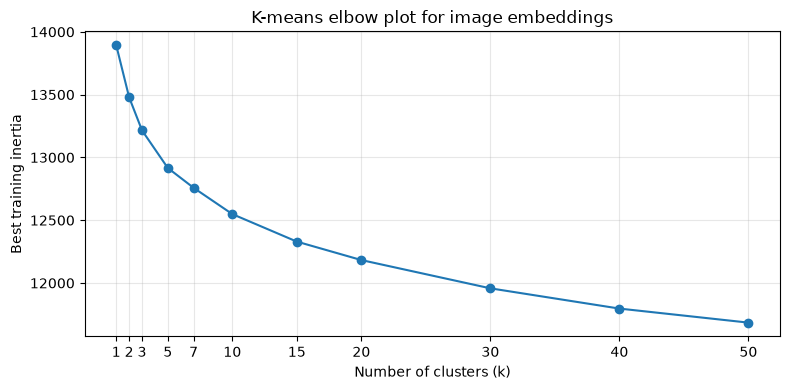

In [9]:
image_k_values = [1, 2, 3, 5, 7, 10, 15, 20, 30, 40, 50]
image_seeds = [42, 43, 44]

best_image_centers_by_k = {}
best_image_inertias = []

for k in image_k_values:
    best_inertia = np.inf

    for seed in image_seeds:
        centers = fit_kmeans(X_img_train, k=k, seed=seed)
        inertia = calculate_inertia(X_img_train, centers)

        if inertia < best_inertia:
            best_inertia = inertia
            best_image_centers_by_k[k] = centers

    best_image_inertias.append(best_inertia)
    print(f"k={k:2d} | Best training inertia: {best_inertia:,.2f}")

plt.figure(figsize=(8, 4))
plt.plot(image_k_values, best_image_inertias, marker="o")
plt.xticks(image_k_values)
plt.xlabel("Number of clusters (k)")
plt.ylabel("Best training inertia")
plt.title("K-means elbow plot for image embeddings")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 2. Clustering sentiments

k=1 | best inertia=269,119.02 | seed=42
k=2 | best inertia=258,531.59 | seed=44
k=3 | best inertia=252,237.60 | seed=44
k=4 | best inertia=247,223.87 | seed=42
k=5 | best inertia=243,180.05 | seed=45
k=6 | best inertia=240,075.06 | seed=45
k=7 | best inertia=237,453.97 | seed=45
k=8 | best inertia=235,246.44 | seed=46
k=9 | best inertia=233,406.49 | seed=46
k=10 | best inertia=230,884.40 | seed=43
k=11 | best inertia=229,522.09 | seed=42
k=12 | best inertia=227,983.10 | seed=46
k=13 | best inertia=226,741.16 | seed=42
k=14 | best inertia=225,209.31 | seed=42
k=15 | best inertia=224,222.97 | seed=44
k=16 | best inertia=223,219.72 | seed=42
k=17 | best inertia=222,327.38 | seed=44
k=18 | best inertia=221,318.23 | seed=43
k=19 | best inertia=220,471.34 | seed=45


,k,Best training inertia,Best seed
0,1,269119.016612,42
1,2,258531.592464,44
2,3,252237.602705,44
3,4,247223.870169,42
4,5,243180.045435,45
5,6,240075.058641,45
6,7,237453.969387,45
7,8,235246.438756,46
8,9,233406.491516,46
9,10,230884.402878,43


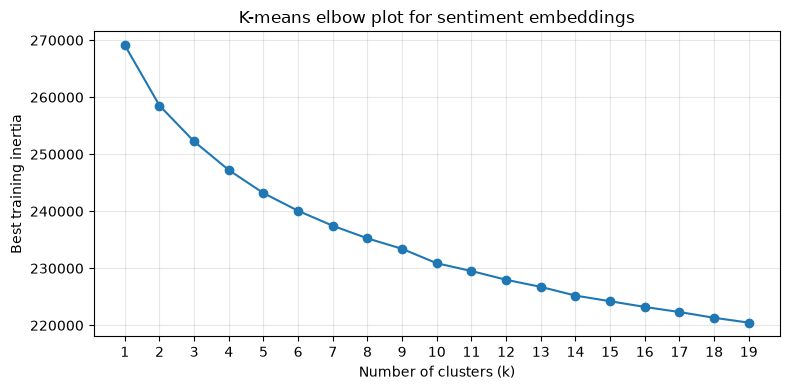

In [10]:
k_values = range(1, 20)
seeds = [42, 43, 44, 45, 46]

best_centers_by_k = {}
results = []

for k in k_values:
    best_inertia = np.inf
    best_seed = None

    for seed in seeds:
        centers = fit_kmeans(X_sent_train, k=k, seed=seed)
        inertia = calculate_inertia(X_sent_train, centers)

        if inertia < best_inertia:
            best_inertia = inertia
            best_seed = seed
            best_centers_by_k[k] = centers

    results.append({
        "k": k,
        "Best training inertia": best_inertia,
        "Best seed": best_seed,
    })

    print(f"k={k} | best inertia={best_inertia:,.2f} | seed={best_seed}")

elbow_results = pd.DataFrame(results)
display(elbow_results)

plt.figure(figsize=(8, 4))
plt.plot(elbow_results["k"], elbow_results["Best training inertia"], marker="o")
plt.xticks(list(k_values))
plt.xlabel("Number of clusters (k)")
plt.ylabel("Best training inertia")
plt.title("K-means elbow plot for sentiment embeddings")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 3. Analyzing the clusters

3.1 Evaluating how closely the clusters match the labels they have using the ARI.

ARI -> adjusted rand index, checks whether pairs from different classes tend to be in the same cluster, 1 being perfect agreement or identical clustering and 0 being chance-level agrrement or random labeling


In [11]:
sentiment_names = {0: "Negative", 1: "Neutral", 2: "Positive"}

for k in [3, 6]:
    counts, percentages, ari = analyze_clusters(
        X_sent_val, y_sent_val, best_centers_by_k[k]
    )

    print(f"Sentiment | k={k} | ARI={ari:.3f}")
    display(
        percentages.rename(columns=sentiment_names)
        .round(1)
        .assign(Size=counts.sum(axis=1))
    )


for k in [10, 20, 50]:
    counts, percentages, ari = analyze_clusters(
        X_img_val, y_img_val, best_image_centers_by_k[k]
    )

    print(f"\nImages | k={k} | ARI={ari:.3f}")

    for cluster_id, row in percentages.iterrows():
        size = counts.loc[cluster_id].sum()
        if size == 0:
            print(f"Cluster {cluster_id}: no validation images")
            continue

        top_classes = row[row > 0].nlargest(3)
        summary = ", ".join(
            f"class {label} ({share:.1f}%)"
            for label, share in top_classes.items()
        )
        print(f"Cluster {cluster_id} ({size} images): {summary}")

Sentiment | k=3 | ARI=0.016


True class,Negative,Neutral,Positive,Size
Cluster,,,,
0,36.5,26.1,37.4,736
1,28.3,32.2,39.5,891
2,36.1,41.5,22.4,773


Sentiment | k=6 | ARI=0.018


True class,Negative,Neutral,Positive,Size
Cluster,,,,
0,32.2,32.7,35.1,652
1,38.5,24.8,36.7,561
2,16.0,54.0,30.0,50
3,22.5,47.0,30.5,249
4,46.9,38.0,15.1,437
5,23.3,30.6,46.1,451



Images | k=10 | ARI=0.004
Cluster 0 (529 images): class 47 (5.7%), class 48 (3.8%), class 6 (3.6%)
Cluster 1 (169 images): class 9 (6.5%), class 27 (5.9%), class 31 (5.9%)
Cluster 2 (334 images): class 21 (3.6%), class 42 (3.6%), class 4 (3.3%)
Cluster 3 (127 images): class 33 (11.0%), class 11 (10.2%), class 32 (7.1%)
Cluster 4 (1301 images): class 23 (3.3%), class 24 (3.3%), class 3 (3.1%)
Cluster 5 (342 images): class 42 (3.8%), class 25 (3.5%), class 19 (3.2%)
Cluster 6 (345 images): class 49 (7.2%), class 8 (6.4%), class 5 (5.5%)
Cluster 7 (407 images): class 46 (8.8%), class 7 (3.2%), class 22 (3.2%)
Cluster 8 (349 images): class 14 (3.7%), class 44 (3.7%), class 48 (3.7%)
Cluster 9 (97 images): class 38 (8.2%), class 45 (8.2%), class 31 (6.2%)

Images | k=20 | ARI=0.012
Cluster 0 (144 images): class 4 (6.9%), class 46 (5.6%), class 17 (4.9%)
Cluster 1 (156 images): class 8 (12.8%), class 49 (10.9%), class 40 (5.8%)
Cluster 2 (104 images): class 21 (7.7%), class 27 (6.7%), class

3.2 Finding out which image classes end up clustered up together often using only k = 5.

In [13]:
chosen_k = 5

image_counts, _, _ = analyze_clusters(
    X_img_val, y_img_val, best_image_centers_by_k[chosen_k]
)

# Each column shows how that class is distributed across clusters.
class_distributions = image_counts.div(image_counts.sum(axis=0), axis=1)

pairs = []

for class_a, class_b in combinations(class_distributions.columns, 2):
    same_cluster_rate = (
        class_distributions[class_a] * class_distributions[class_b]
    ).sum()

    pairs.append({
        "Class A": class_a,
        "Class B": class_b,
        "Same cluster (%)": 100 * same_cluster_rate,
    })

top_pairs = pd.DataFrame(pairs).nlargest(10, "Same cluster (%)")
display(top_pairs.round(1))

,Class A,Class B,Same cluster (%)
1082,32,43,52.6
742,18,32,51.0
1072,32,33,50.8
753,18,43,50.4
1098,33,43,50.3
1079,32,40,50.0
1182,40,43,49.5
743,18,33,49.0
261,5,32,48.5
882,23,32,48.4
